# Reproduce FastBN
> **Môi trường yêu cầu**: Chạy trong môi trường conda `islp` (đã cài đặt `matplotlib`, `pandas`, `jupyter`, `numpy`).

In [11]:
import os
import re
import random
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else "/home/uyenuyen/c_project/FastPGM"
FASTPGM_BIN  = os.path.join(PROJECT_ROOT, "build", "fastpgm")
DATASET_DIR  = os.path.join(PROJECT_ROOT, "dataset")
FIGURES_DIR  = os.path.join(PROJECT_ROOT, "notebooks", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

NETWORKS = ["alarm", "insurance", "hepar2", "munin1"]
TITLES   = {
    "alarm": "(a) Alarm",
    "insurance": "(b) Insurance",
    "hepar2": "(c) Hepar2",
    "munin1": "(d) Munin1"
}

print("PROJECT_ROOT:", PROJECT_ROOT)
print("FASTPGM_BIN :", FASTPGM_BIN)
print("FIGURES_DIR :", FIGURES_DIR)

PROJECT_ROOT: /home/uyenuyen/c_project/FastPGM
FASTPGM_BIN : /home/uyenuyen/c_project/FastPGM/build/fastpgm
FIGURES_DIR : /home/uyenuyen/c_project/FastPGM/notebooks/figures


## 1. Kiểm tra & Sinh dữ liệu mẫu (`s5000`, `s10000`, `s15000`) từ file `.bif`
Nếu bất kỳ tập mẫu nào trong 4 mạng (`alarm`, `insurance`, `hepar2`, `munin1`) chưa tồn tại, hàm dưới đây sẽ đọc trực tiếp file `.bif` và sinh mẫu theo thứ tự tô-pô.

In [12]:
def parse_bif_and_sample_csv(bif_path, out_path, n_samples, seed=42):
    with open(bif_path, "r") as f:
        text = f.read()
    var_order, states = [], {}
    for m in re.finditer(r"variable\s+(\S+)\s*\{\s*type\s+discrete\s*\[\s*\d+\s*\]\s*\{\s*([^}]+)\}", text):
        var = m.group(1)
        vals = [v.strip().rstrip(",") for v in m.group(2).replace(",", " ").split() if v.strip()]
        var_order.append(var)
        states[var] = vals

    parents, cpts = {}, {}
    for m in re.finditer(r"probability\s*\(\s*([^)]+)\)\s*\{([^}]+)\}", text):
        header, body = m.group(1).strip(), m.group(2).strip()
        if "|" in header:
            child, par_str = header.split("|")
            child = child.strip()
            pars = [p.strip().rstrip(",") for p in par_str.replace(",", " ").split() if p.strip()]
        else:
            child, pars = header.strip(), []
        parents[child] = pars
        if not pars:
            tm = re.search(r"table\s+([^;]+);", body)
            probs = [float(x) for x in tm.group(1).replace(",", " ").split()]
            cpts[child] = probs
        else:
            table = {}
            for line in body.splitlines():
                line = line.strip()
                if line.startswith("("):
                    tup_str, prob_str = line.split(")")
                    key = tuple(v.strip() for v in tup_str[1:].split(","))
                    probs = [float(x) for x in prob_str.rstrip(";").replace(",", " ").split()]
                    table[key] = probs
            cpts[child] = table

    topo, visited = [], set()
    while len(topo) < len(var_order):
        for v in var_order:
            if v not in visited and all(p in visited for p in parents[v]):
                topo.append(v)
                visited.add(v)

    rng = random.Random(seed)
    with open(out_path, "w") as out:
        out.write(",".join(var_order) + "\n")
        for _ in range(n_samples):
            row = {}
            for v in topo:
                vals = states[v]
                probs = cpts[v] if not parents[v] else cpts[v][tuple(row[p] for p in parents[v])]
                row[v] = rng.choices(vals, weights=probs, k=1)[0]
            out.write(",".join(row[v] for v in var_order) + "\n")
    print("Đã sinh:", out_path)

for net in NETWORKS:
    bif = os.path.join(DATASET_DIR, net, f"{net}.bif")
    for n in [5000, 10000, 15000]:
        out = os.path.join(DATASET_DIR, net, f"{net}_s{n}")
        if not os.path.exists(out):
            parse_bif_and_sample_csv(bif, out, n, seed=n)
        else:
            print(f"[OK] Đã có sẵn: {out}")

[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/alarm/alarm_s5000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/alarm/alarm_s10000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/alarm/alarm_s15000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/insurance/insurance_s5000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/insurance/insurance_s10000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/insurance/insurance_s15000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/hepar2/hepar2_s5000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/hepar2/hepar2_s10000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/hepar2/hepar2_s15000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/munin1/munin1_s5000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/munin1/munin1_s10000
[OK] Đã có sẵn: /home/uyenuyen/c_project/FastPGM/dataset/munin1/munin1_s15000


## 2. Hàm gọi `./fastpgm` và trích xuất thời gian thực thi + số phép kiểm định CI

In [13]:
def run_fastpgm(net, sample_size, threads, group_size=1, parallelism_type=0):
    """Chạy ./fastpgm và trả về (thời gian pc-stable (giây), tổng số CI tests).
    parallelism_type: 0 = CI-level (mặc định), 1 = Edge-level, 2 = Sample-level
    """
    cmd = [
        FASTPGM_BIN,
        "-j", "0", "-m", "0",
        "-t", str(threads),
        "-p", str(parallelism_type),
        "-g", str(group_size),
        "-a", "0.05",
        "-ss", "0",
        "-f2", f"{net}/{net}_s{sample_size}"
    ]
    res = subprocess.run(cmd, cwd=PROJECT_ROOT, capture_output=True, text=True, check=True)
    time_m = re.search(r"pc-stable:\s*([0-9.eE+-]+)\s*s", res.stdout)
    ci_m   = re.search(r"# of CI-tests =\s*(\d+)", res.stdout)
    return float(time_m.group(1)), int(ci_m.group(1))


## 3. Speedup theo Số luồng và Kích thước mẫu

In [14]:
THREADS_LIST = [1,2,3,4,5,6,7,8,9,10,11,12]
SAMPLE_SIZES = [5000, 10000, 15000]
fig3_csv = os.path.join(FIGURES_DIR, "fig3_results.csv")

if os.path.exists(fig3_csv):
    print(f"Đọc kết quả đã lưu từ {fig3_csv}")
    df_fig3 = pd.read_csv(fig3_csv)
else:
    fig3_records = []
    for net in NETWORKS:
        for s in SAMPLE_SIZES:
            t1_time = None
            for t in THREADS_LIST:
                exec_time, ci_tests = run_fastpgm(net, s, threads=t, group_size=1)
                if t == 1:
                    t1_time = exec_time
                speedup = t1_time / exec_time
                fig3_records.append({
                    "net": net, "samples": s, "threads": t,
                    "time": exec_time, "speedup": speedup, "ci_tests": ci_tests
                })
                print(f"[Fig.3] {net:9s} | s={s:5d} | t={t:2d} -> time={exec_time:.4f}s | speedup={speedup:.2f}x")
    df_fig3 = pd.DataFrame(fig3_records)
    df_fig3.to_csv(fig3_csv, index=False)

display(df_fig3.head(15))

[Fig.3] alarm     | s= 5000 | t= 1 -> time=0.0776s | speedup=1.00x
[Fig.3] alarm     | s= 5000 | t= 2 -> time=0.0512s | speedup=1.52x
[Fig.3] alarm     | s= 5000 | t= 3 -> time=0.0361s | speedup=2.15x
[Fig.3] alarm     | s= 5000 | t= 4 -> time=0.0299s | speedup=2.59x
[Fig.3] alarm     | s= 5000 | t= 5 -> time=0.0267s | speedup=2.91x
[Fig.3] alarm     | s= 5000 | t= 6 -> time=0.0237s | speedup=3.27x
[Fig.3] alarm     | s= 5000 | t= 7 -> time=0.0256s | speedup=3.03x
[Fig.3] alarm     | s= 5000 | t= 8 -> time=0.0262s | speedup=2.96x
[Fig.3] alarm     | s= 5000 | t= 9 -> time=0.0252s | speedup=3.07x
[Fig.3] alarm     | s= 5000 | t=10 -> time=0.0249s | speedup=3.12x
[Fig.3] alarm     | s= 5000 | t=11 -> time=0.0274s | speedup=2.83x
[Fig.3] alarm     | s= 5000 | t=12 -> time=0.1664s | speedup=0.47x
[Fig.3] alarm     | s=10000 | t= 1 -> time=0.1508s | speedup=1.00x
[Fig.3] alarm     | s=10000 | t= 2 -> time=0.0825s | speedup=1.83x
[Fig.3] alarm     | s=10000 | t= 3 -> time=0.0657s | speedup=2

,net,samples,threads,time,speedup,ci_tests
0,alarm,5000,1,0.077553,1.000000,5206
1,alarm,5000,2,0.051185,1.515165,5206
2,alarm,5000,3,0.036050,2.151243,5206
3,alarm,5000,4,0.029939,2.590380,5206
4,alarm,5000,5,0.026655,2.909471,5206
5,alarm,5000,6,0.023742,3.266507,5206
6,alarm,5000,7,0.025573,3.032687,5206
7,alarm,5000,8,0.026168,2.963718,5206
8,alarm,5000,9,0.025230,3.073844,5206
9,alarm,5000,10,0.024895,3.115232,5206


Đã lưu hình Fig. 3 tại: /home/uyenuyen/c_project/FastPGM/notebooks/figures/fig3_speedup_sample_size.png


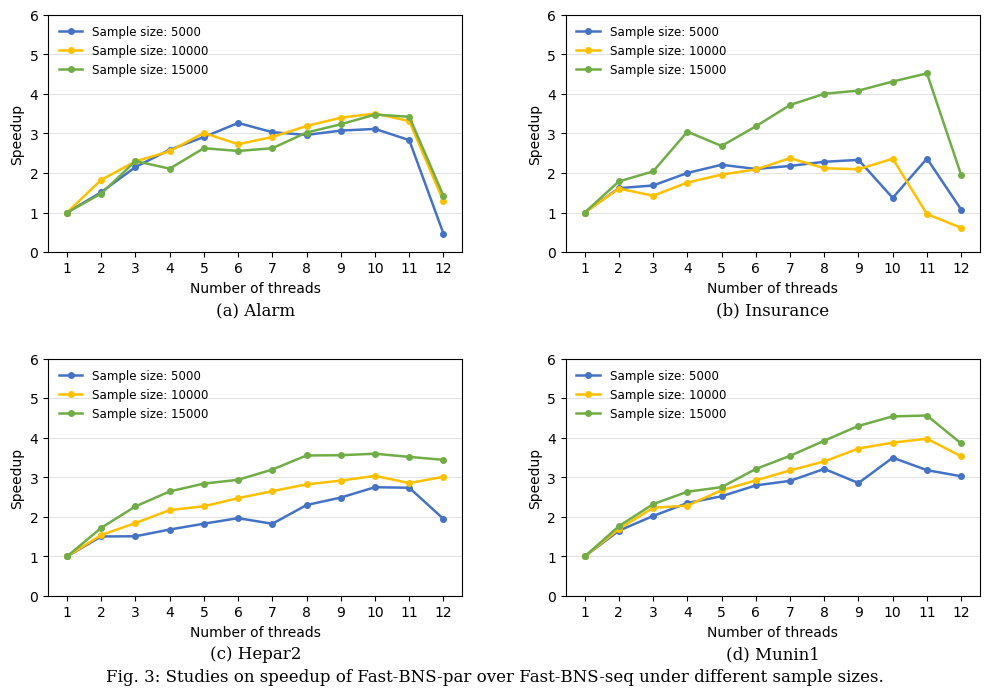

In [15]:
# Vẽ biểu đồ Fig. 3 và lưu vào notebooks/figures/
fig, axes = plt.subplots(2, 2, figsize=(10, 7.2))
colors = {5000: "#4472C4", 10000: "#FFC000", 15000: "#70AD47"}

for ax, net in zip(axes.flat, NETWORKS):
    sub = df_fig3[df_fig3["net"] == net]
    for s in SAMPLE_SIZES:
        s_df = sub[sub["samples"] == s]
        ax.plot(
            [str(t) for t in s_df["threads"]],
            s_df["speedup"],
            marker="o", markersize=4, linewidth=1.8,
            color=colors[s], label=f"Sample size: {s}"
        )
    ax.set_xlabel("Number of threads", fontsize=10)
    ax.set_ylabel("Speedup", fontsize=10)
    ax.set_ylim(0, max(sub["speedup"].max() * 1.15, 6))
    ax.set_title(TITLES[net], y=-0.30, fontsize=12, fontfamily="serif")
    ax.grid(axis="y", linestyle="-", alpha=0.35)
    ax.legend(fontsize=8.5, frameon=False, loc="upper left")

plt.suptitle("Fig. 3: Studies on speedup of Fast-BNS-par over Fast-BNS-seq under different sample sizes.", y=0.02, fontsize=12, fontfamily="serif")
plt.tight_layout()
plt.subplots_adjust(bottom=0.12, hspace=0.45, wspace=0.25)

fig3_png = os.path.join(FIGURES_DIR, "fig3_speedup_sample_size.png")
plt.savefig(fig3_png, dpi=300, bbox_inches="tight")
print("Đã lưu hình Fig. 3 tại:", fig3_png)
plt.show()

## 4. `Group size` (`gs`) vs Thời gian thực thi & Số lượng CI tests

In [25]:
GROUP_SIZES = [1, 2, 4, 6, 8, 10, 12, 14, 16]
NUM_THREADS_FIG4 = 1
fig4_csv = os.path.join(FIGURES_DIR, "fig4_results.csv")

if os.path.exists(fig4_csv):
    print(f"Đọc kết quả đã lưu từ {fig4_csv} (xóa file này nếu muốn chạy lại từ đầu)...")
    df_fig4 = pd.read_csv(fig4_csv)
else:
    fig4_records = []
    for net in NETWORKS:
        base_ci = None
        for gs in GROUP_SIZES:
            exec_time, ci_tests = run_fastpgm(net, sample_size=10000, threads=NUM_THREADS_FIG4, group_size=gs)
            if gs == 1:
                base_ci = ci_tests
            inc_pct = (ci_tests - base_ci) / base_ci * 100.0
            fig4_records.append({
                "net": net, "gs": gs, "time": exec_time,
                "ci_tests": ci_tests, "inc_pct": inc_pct
            })
            print(f"[Fig.4] {net:9s} | gs={gs:2d} -> time={exec_time:.4f}s | CI={ci_tests} (+{inc_pct:.2f}%)")
    df_fig4 = pd.DataFrame(fig4_records)
    df_fig4.to_csv(fig4_csv, index=False)

display(df_fig4.head(18))

[Fig.4] alarm     | gs= 1 -> time=0.1355s | CI=6265 (+0.00%)
[Fig.4] alarm     | gs= 2 -> time=0.1477s | CI=6399 (+2.14%)
[Fig.4] alarm     | gs= 4 -> time=0.1358s | CI=6657 (+6.26%)
[Fig.4] alarm     | gs= 6 -> time=0.1291s | CI=6905 (+10.22%)
[Fig.4] alarm     | gs= 8 -> time=0.1526s | CI=7188 (+14.73%)
[Fig.4] alarm     | gs=10 -> time=0.1460s | CI=7310 (+16.68%)
[Fig.4] alarm     | gs=12 -> time=0.1516s | CI=7489 (+19.54%)
[Fig.4] alarm     | gs=14 -> time=0.1496s | CI=7620 (+21.63%)
[Fig.4] alarm     | gs=16 -> time=0.1541s | CI=7736 (+23.48%)
[Fig.4] insurance | gs= 1 -> time=0.3113s | CI=9825 (+0.00%)
[Fig.4] insurance | gs= 2 -> time=0.3509s | CI=9942 (+1.19%)
[Fig.4] insurance | gs= 4 -> time=0.3202s | CI=10186 (+3.67%)
[Fig.4] insurance | gs= 6 -> time=0.3153s | CI=10450 (+6.36%)
[Fig.4] insurance | gs= 8 -> time=0.3203s | CI=10762 (+9.54%)
[Fig.4] insurance | gs=10 -> time=0.3193s | CI=11072 (+12.69%)
[Fig.4] insurance | gs=12 -> time=0.3426s | CI=11477 (+16.81%)
[Fig.4] ins

,net,gs,time,ci_tests,inc_pct
0,alarm,1,0.135516,6265,0.000000
1,alarm,2,0.147691,6399,2.138867
2,alarm,4,0.135784,6657,6.256983
3,alarm,6,0.129051,6905,10.215483
4,alarm,8,0.152555,7188,14.732642
5,alarm,10,0.146046,7310,16.679968
6,alarm,12,0.151611,7489,19.537111
7,alarm,14,0.149563,7620,21.628093
8,alarm,16,0.154149,7736,23.479649
9,insurance,1,0.311336,9825,0.000000


Đã lưu hình Fig. 4 tại: /home/uyenuyen/c_project/FastPGM/notebooks/figures/fig4_group_size_effect.png


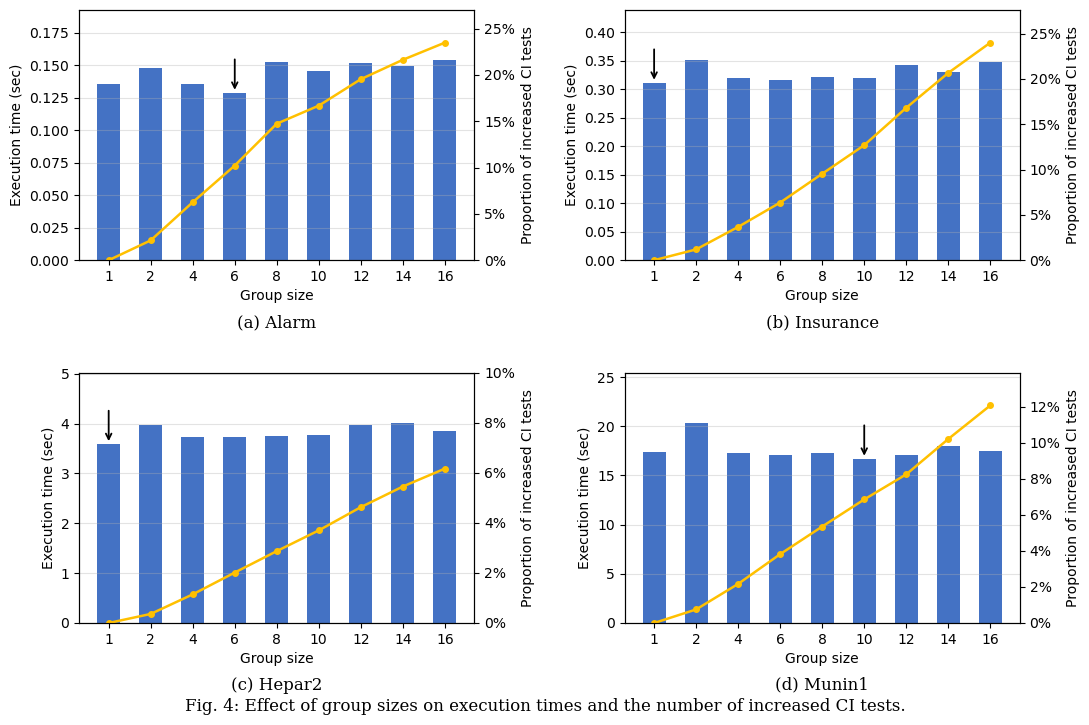

In [26]:
# Vẽ biểu đồ Fig. 4 và lưu vào notebooks/figures/
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))

for ax1, net in zip(axes.flat, NETWORKS):
    sub = df_fig4[df_fig4["net"] == net].reset_index(drop=True)
    x = np.arange(len(sub))

    # Trục trái (Cột xanh): Execution time (sec)
    ax1.bar(x, sub["time"], width=0.55, color="#4472C4")
    ax1.set_xticks(x)
    ax1.set_xticklabels(sub["gs"])
    ax1.set_xlabel("Group size", fontsize=10)
    ax1.set_ylabel("Execution time (sec)", fontsize=10)
    ax1.set_ylim(0, sub["time"].max() * 1.25)
    ax1.grid(axis="y", linestyle="-", alpha=0.35)

    # Vẽ mũi tên đen chỉ vào Group size có thời gian chạy ngắn nhất
    best_idx = sub["time"].idxmin()
    best_y   = sub.loc[best_idx, "time"]
    ax1.annotate(
        "",
        xy=(best_idx, best_y),
        xytext=(best_idx, best_y + sub["time"].max() * 0.18),
        arrowprops=dict(arrowstyle="->", color="black", lw=1.3)
    )

    # Trục phải (Đường vàng): Proportion of increased CI tests (%)
    ax2 = ax1.twinx()
    ax2.plot(x, sub["inc_pct"], color="#FFC000", marker="o", markersize=4, linewidth=1.8)
    ax2.set_ylabel("Proportion of increased CI tests", fontsize=10)
    ax2.set_ylim(0, max(sub["inc_pct"].max() * 1.15, 10))
    ax2.yaxis.set_major_formatter(lambda val, pos: f"{int(round(val))}%")

    ax1.set_title(TITLES[net], y=-0.30, fontsize=12, fontfamily="serif")

plt.suptitle("Fig. 4: Effect of group sizes on execution times and the number of increased CI tests.", y=0.02, fontsize=12, fontfamily="serif")
plt.tight_layout()
plt.subplots_adjust(bottom=0.12, hspace=0.45, wspace=0.38)

fig4_png = os.path.join(FIGURES_DIR, "fig4_group_size_effect.png")
plt.savefig(fig4_png, dpi=300, bbox_inches="tight")
print("Đã lưu hình Fig. 4 tại:", fig4_png)
plt.show()

## 5. So sánh 3 hướng song song hóa: CI-level, Edge-level, Sample-level

Theo Mục IV-A & V-C trong bài báo:
1. **CI-level parallelism (Fast-BNS)**: Tận dụng cơ chế *dynamic work pool* phân phối các nhóm CI tests giữa các luồng, cân bằng tải động và loại bỏ hoàn toàn các phép toán `atomic` trên bảng tần số (contingency table).
2. **Edge-level parallelism**: Phân phối song song theo từng cạnh ở mỗi độ sâu (*depth*). Hạn chế là các cạnh có số lượng CI test rất chênh lệch, dẫn đến mất cân bằng tải giữa các luồng.
3. **Sample-level parallelism**: Song song hóa việc duyệt qua các mẫu bên trong từng CI test. Hạn chế là chi phí khởi tạo luồng liên tục cho mỗi CI test và xung đột ghi trên bảng tần số đòi hỏi nhiều phép toán `#pragma omp atomic`, khiến thời gian thực thi tăng vọt.

In [19]:
fig2_csv = os.path.join(FIGURES_DIR, "fig2_results.csv")
GRANULARITIES = [
    (0, "CI-level", "#1f77b4", "s"),      # Xanh lam, vuông
    (1, "Edge-level", "#ff7f0e", "d"),    # Vàng cam, thoi
    (2, "Sample-level", "#2ca02c", "^")   # Xanh lục, tam giác
]

if os.path.exists(fig2_csv):
    print(f"Nạp kết quả Fig. 2 sẵn có từ: {fig2_csv}")
    df_fig2 = pd.read_csv(fig2_csv)
else:
    print("Chạy benchmark Fig. 2 trên 4 bộ dữ liệu với 5000 mẫu...")
    rows_fig2 = []
    for net in NETWORKS:
        print(f"--- Dataset: {net} ---")
        for par_type, par_name, _, _ in GRANULARITIES:
            for t in THREADS_LIST:
                t_sec, ci_cnt = run_fastpgm(net, 5000, t, group_size=1, parallelism_type=par_type)
                print(f"{net} | {par_name:12} | threads={t:2d} -> time={t_sec:.4f}s, CI-tests={ci_cnt}")
                rows_fig2.append({
                    "dataset": net,
                    "parallelism_type": par_type,
                    "granularity": par_name,
                    "threads": t,
                    "execution_time": t_sec,
                    "ci_tests": ci_cnt
                })
    df_fig2 = pd.DataFrame(rows_fig2)
    df_fig2.to_csv(fig2_csv, index=False)
    print(f"Đã lưu kết quả Fig. 2 vào: {fig2_csv}")

df_fig2.head(15)


Chạy benchmark Fig. 2 trên 4 bộ dữ liệu với 5000 mẫu...
--- Dataset: alarm ---
alarm | CI-level     | threads= 1 -> time=0.0618s, CI-tests=5206
alarm | CI-level     | threads= 2 -> time=0.0351s, CI-tests=5206
alarm | CI-level     | threads= 3 -> time=0.0253s, CI-tests=5206
alarm | CI-level     | threads= 4 -> time=0.0210s, CI-tests=5206
alarm | CI-level     | threads= 5 -> time=0.0241s, CI-tests=5206
alarm | CI-level     | threads= 6 -> time=0.0228s, CI-tests=5206
alarm | CI-level     | threads= 7 -> time=0.0208s, CI-tests=5206
alarm | CI-level     | threads= 8 -> time=0.0192s, CI-tests=5206
alarm | CI-level     | threads= 9 -> time=0.0179s, CI-tests=5206
alarm | CI-level     | threads=10 -> time=0.0208s, CI-tests=5206
alarm | CI-level     | threads=11 -> time=0.0196s, CI-tests=5206
alarm | CI-level     | threads=12 -> time=0.1463s, CI-tests=5206
alarm | Edge-level   | threads= 1 -> time=0.0666s, CI-tests=5206
alarm | Edge-level   | threads= 2 -> time=0.0406s, CI-tests=5206
alarm | Edg

,dataset,parallelism_type,granularity,threads,execution_time,ci_tests
0,alarm,0,CI-level,1,0.061811,5206
1,alarm,0,CI-level,2,0.035092,5206
2,alarm,0,CI-level,3,0.025251,5206
3,alarm,0,CI-level,4,0.020953,5206
4,alarm,0,CI-level,5,0.024110,5206
5,alarm,0,CI-level,6,0.022789,5206
6,alarm,0,CI-level,7,0.020844,5206
7,alarm,0,CI-level,8,0.019199,5206
8,alarm,0,CI-level,9,0.017862,5206
9,alarm,0,CI-level,10,0.020804,5206


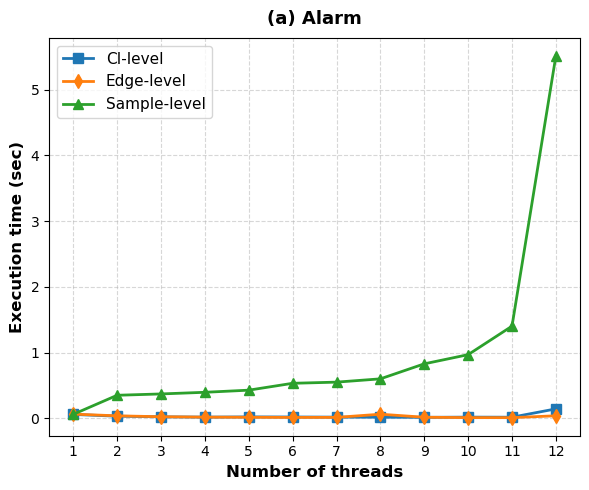

Đã lưu: /home/uyenuyen/c_project/FastPGM/notebooks/figures/fig2_alarm.png


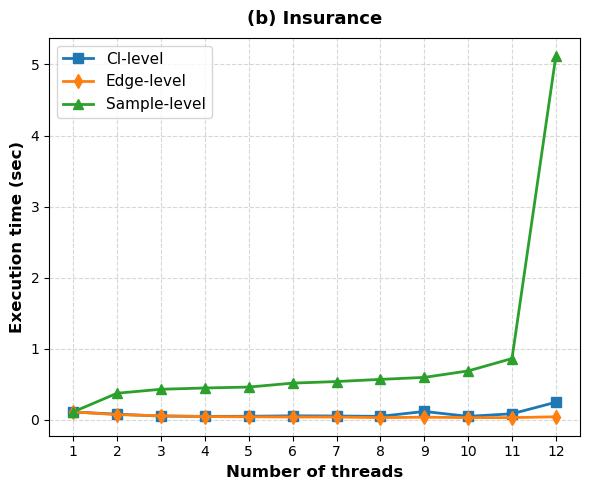

Đã lưu: /home/uyenuyen/c_project/FastPGM/notebooks/figures/fig2_insurance.png


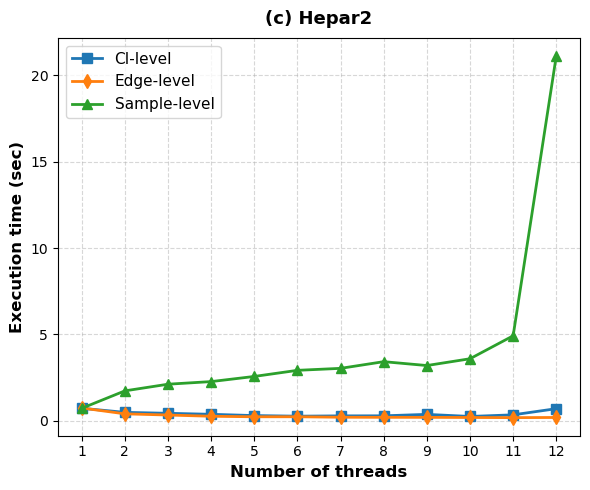

Đã lưu: /home/uyenuyen/c_project/FastPGM/notebooks/figures/fig2_hepar2.png


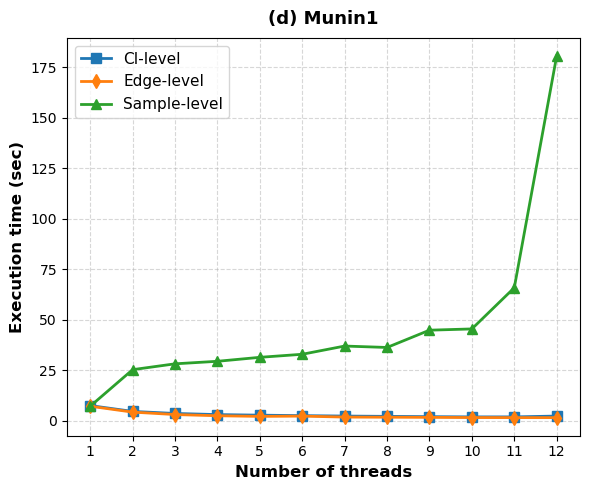

Đã lưu: /home/uyenuyen/c_project/FastPGM/notebooks/figures/fig2_munin1.png


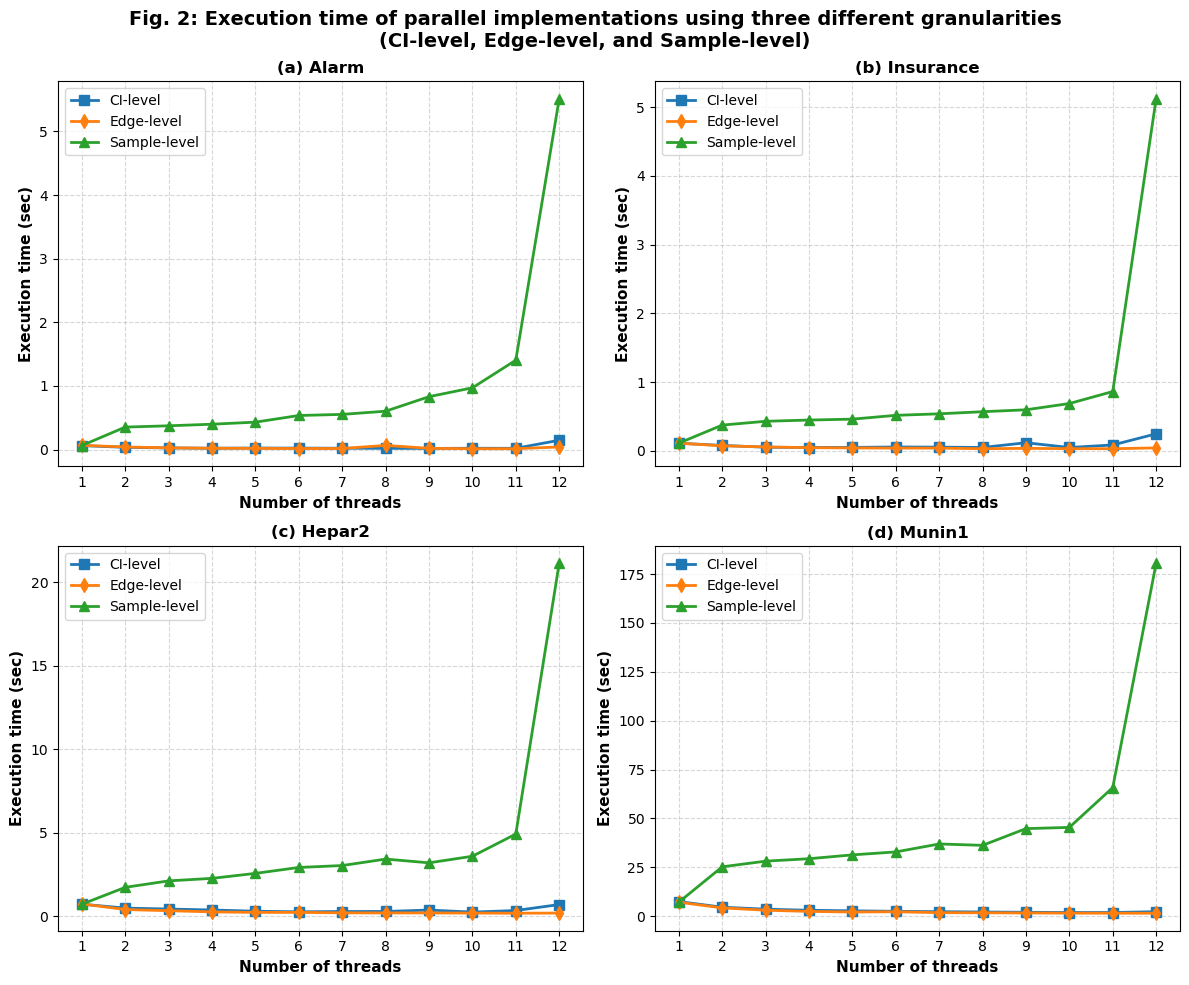

Đã lưu biểu đồ tổng hợp: /home/uyenuyen/c_project/FastPGM/notebooks/figures/fig2_granularity_comparison.png


In [20]:
# Vẽ đồ thị Fig. 2:
# 1. Vẽ 4 biểu đồ riêng biệt (mỗi bộ dữ liệu một hình)
for net in NETWORKS:
    plt.figure(figsize=(6, 5))
    sub_df = df_fig2[df_fig2["dataset"] == net]
    for par_type, par_name, color, marker in GRANULARITIES:
        g_df = sub_df[sub_df["granularity"] == par_name].sort_values("threads")
        plt.plot(g_df["threads"], g_df["execution_time"],
                 label=par_name, color=color, marker=marker, linewidth=2, markersize=7)
    plt.xlabel("Number of threads", fontsize=12, fontweight="bold")
    plt.ylabel("Execution time (sec)", fontsize=12, fontweight="bold")
    plt.title(TITLES[net], fontsize=13, fontweight="bold", pad=10)
    plt.xticks(THREADS_LIST)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(frameon=True, fontsize=11)
    plt.tight_layout()
    
    out_png = os.path.join(FIGURES_DIR, f"fig2_{net}.png")
    plt.savefig(out_png, dpi=300)
    plt.show()
    print(f"Đã lưu: {out_png}")

# 2. Vẽ biểu đồ tổng hợp 4 subplot (2x2) theo phong cách bài báo
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
for idx, net in enumerate(NETWORKS):
    ax = axes[idx]
    sub_df = df_fig2[df_fig2["dataset"] == net]
    for par_type, par_name, color, marker in GRANULARITIES:
        g_df = sub_df[sub_df["granularity"] == par_name].sort_values("threads")
        ax.plot(g_df["threads"], g_df["execution_time"],
                label=par_name, color=color, marker=marker, linewidth=2, markersize=7)
    ax.set_xlabel("Number of threads", fontsize=11, fontweight="bold")
    ax.set_ylabel("Execution time (sec)", fontsize=11, fontweight="bold")
    ax.set_title(TITLES[net], fontsize=12, fontweight="bold")
    ax.set_xticks(THREADS_LIST)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(frameon=True, fontsize=10)

fig.suptitle("Fig. 2: Execution time of parallel implementations using three different granularities\n(CI-level, Edge-level, and Sample-level)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
comb_png = os.path.join(FIGURES_DIR, "fig2_granularity_comparison.png")
plt.savefig(comb_png, dpi=300)
plt.show()
print(f"Đã lưu biểu đồ tổng hợp: {comb_png}")
